# Practical Assignment 1 â€” Part III (metric learning + retrieval evaluation)

1. Evaluate retrieval (P@1, P@5, mAP) using the embeddings extracted from the Part II classification models (produced in `APA2026_Part3_retrieval.ipynb`).
2. Fine-tune ResNet-18 and MobileNetV3-Large with **Triplet Loss** on the STL-10 training split, starting from the Part II pre-trained weights (final classification layer removed).
3. Re-extract query/gallery embeddings using the triplet-trained backbones (same split as Part III retrieval), evaluate P@1, P@5, mAP, and compare against the classification embeddings.


In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Imports

In [17]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as tt
from torchvision.datasets import STL10
from torch.utils.data import Dataset, DataLoader, Subset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


## 2. Settings (match Part II and the Part III retrieval notebook)

In [18]:
RESNET_NAME    = 'resnet18'
MOBILENET_NAME = 'mobilenet_v3_large'

RESNET_PATH    = '/content/resnet_pretrained.pt'
MOBILENET_PATH = '/content/mobilenet_pretrained.pt'

RETRIEVAL_PATH = 'retrieval_part3.pt'

IMG_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

NUM_CLASSES = 10
TOP_K = 5

TRIPLET_MARGIN = 1.0
TRIPLET_EPOCHS = 10
TRIPLET_BATCH  = 64
TRIPLET_LR     = 1e-4

## 3. Load Part III retrieval artefacts (classification embeddings + split)

In [19]:
retrieval = torch.load(RETRIEVAL_PATH, map_location='cpu', weights_only=False)

query_idx      = retrieval['query_idx'].numpy()
gallery_idx    = retrieval['gallery_idx'].numpy()
query_labels   = retrieval['query_labels']
gallery_labels = retrieval['gallery_labels']
classes        = retrieval['classes']

print('query:', len(query_idx), '| gallery:', len(gallery_idx))
print('models in file:', [k for k in retrieval if k in ('ResNet', 'MobileNetV3')])

query: 1600 | gallery: 6400
models in file: ['ResNet', 'MobileNetV3']


## 4. Retrieval metrics (Precision@K, mean Average Precision)
A gallery image is **relevant** to a query if it belongs to the same class.

In [20]:
@torch.no_grad()
def eval_retrieval(query_emb, gallery_emb, q_labels, g_labels, ks=(1, 5)):
    q = F.normalize(query_emb.float(), dim=1)
    g = F.normalize(gallery_emb.float(), dim=1)
    sim = q @ g.T
    ranking = sim.argsort(dim=1, descending=True)
    q_labels = q_labels.view(-1)
    g_labels = g_labels.view(-1)
    ranked_labels = g_labels[ranking]
    rel = (ranked_labels == q_labels.unsqueeze(1)).float()

    out = {}
    for k in ks:
        out[f'P@{k}'] = rel[:, :k].mean().item() * 100.0

    cum_hits = rel.cumsum(dim=1)
    ranks = torch.arange(1, rel.size(1) + 1, dtype=torch.float32)
    precision_at_k = cum_hits / ranks
    n_rel = rel.sum(dim=1).clamp(min=1)
    ap = (precision_at_k * rel).sum(dim=1) / n_rel
    out['mAP'] = ap.mean().item() * 100.0
    return out

## 5. Evaluate the Part II classification embeddings

In [21]:
cls_results = {}
for name in ('ResNet', 'MobileNetV3'):
    m = eval_retrieval(retrieval[name]['query_emb'], retrieval[name]['gallery_emb'],
                       query_labels, gallery_labels, ks=(1, TOP_K))
    cls_results[f'{name} (classification)'] = m
    print(name, m)

pd.DataFrame(cls_results).T.round(2)

ResNet {'P@1': 94.87500190734863, 'P@5': 94.37500238418579, 'mAP': 92.07831621170044}
MobileNetV3 {'P@1': 96.06249928474426, 'P@5': 95.3374981880188, 'mAP': 90.76526165008545}


,P@1,P@5,mAP
ResNet (classification),94.88,94.38,92.08
MobileNetV3 (classification),96.06,95.34,90.77


## 6. STL-10 train set and triplet sampling
Triplets are built on-the-fly from the STL-10 train split: for each anchor, pick a positive image from the same class and a negative image from a different class.

In [22]:
train_transform = tt.Compose([
    tt.Resize(IMG_SIZE),
    tt.RandomHorizontalFlip(),
    tt.ToTensor(),
    tt.Normalize(MEAN, STD),
])
test_transform = tt.Compose([
    tt.Resize(IMG_SIZE),
    tt.ToTensor(),
    tt.Normalize(MEAN, STD),
])

train_set = STL10(root='./data', split='train', download=True, transform=train_transform)
test_set  = STL10(root='./data', split='test',  download=True, transform=test_transform)
train_labels = np.array(train_set.labels)
print('train:', len(train_set), '| test:', len(test_set))

class TripletDataset(Dataset):
    def __init__(self, base, labels):
        self.base = base
        self.labels = np.asarray(labels)
        self.by_class = {int(c): np.where(self.labels == c)[0] for c in np.unique(self.labels)}
        self.classes = list(self.by_class.keys())

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        anchor_img, c = self.base[i]
        c = int(c)
        pos_pool = self.by_class[c]
        p = i
        while p == i:
            p = int(np.random.choice(pos_pool))
        neg_c = c
        while neg_c == c:
            neg_c = int(np.random.choice(self.classes))
        n = int(np.random.choice(self.by_class[neg_c]))
        pos_img, _ = self.base[p]
        neg_img, _ = self.base[n]
        return anchor_img, pos_img, neg_img

triplet_set = TripletDataset(train_set, train_labels)
triplet_loader = DataLoader(triplet_set, batch_size=TRIPLET_BATCH, shuffle=True, num_workers=2, pin_memory=True)

train: 5000 | test: 8000


## 7. Build the backbones from Part II weights (classification head removed)

In [23]:
def load_weights(model, path):
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(checkpoint, nn.Module):
        return checkpoint
    if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
        checkpoint = checkpoint['model_state_dict']
    model.load_state_dict(checkpoint)
    return model

def build_resnet():
    m = getattr(models, RESNET_NAME)(weights=None)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    m = load_weights(m, RESNET_PATH)
    m.fc = nn.Identity()
    return m

def build_mobilenet():
    m = getattr(models, MOBILENET_NAME)(weights=None)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
    m = load_weights(m, MOBILENET_PATH)
    m.classifier[-1] = nn.Identity()
    return m

## 8. Triplet-loss fine-tuning
`nn.TripletMarginLoss` with the embeddings L2-normalised, so the distance is directly comparable to the cosine ranking used at retrieval time.

In [24]:
def train_triplet(model, loader, epochs=TRIPLET_EPOCHS, lr=TRIPLET_LR, margin=TRIPLET_MARGIN, tag='model'):
    model = model.to(device).train()
    criterion = nn.TripletMarginLoss(margin=margin, p=2)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    history = []
    for epoch in range(epochs):
        running = 0.0
        total = 0
        for a, p, n_img in loader:
            a, p, n_img = a.to(device), p.to(device), n_img.to(device)
            optimizer.zero_grad()
            ea = F.normalize(model(a), dim=1)
            ep = F.normalize(model(p), dim=1)
            en = F.normalize(model(n_img), dim=1)
            loss = criterion(ea, ep, en)
            loss.backward()
            optimizer.step()
            running += loss.item() * a.size(0)
            total += a.size(0)
        avg = running / total
        history.append(avg)
        print(f'[{tag}] epoch {epoch+1}/{epochs} triplet loss: {avg:.4f}')
    return model.eval(), history

In [25]:
resnet_tri,    hist_resnet    = train_triplet(build_resnet(),    triplet_loader, tag='ResNet')
mobilenet_tri, hist_mobilenet = train_triplet(build_mobilenet(), triplet_loader, tag='MobileNetV3')

[ResNet] epoch 1/10 triplet loss: 0.1570
[ResNet] epoch 2/10 triplet loss: 0.0468
[ResNet] epoch 3/10 triplet loss: 0.0224
[ResNet] epoch 4/10 triplet loss: 0.0134
[ResNet] epoch 5/10 triplet loss: 0.0098
[ResNet] epoch 6/10 triplet loss: 0.0070
[ResNet] epoch 7/10 triplet loss: 0.0087
[ResNet] epoch 8/10 triplet loss: 0.0057
[ResNet] epoch 9/10 triplet loss: 0.0054
[ResNet] epoch 10/10 triplet loss: 0.0067
[MobileNetV3] epoch 1/10 triplet loss: 0.4782
[MobileNetV3] epoch 2/10 triplet loss: 0.3191
[MobileNetV3] epoch 3/10 triplet loss: 0.2535
[MobileNetV3] epoch 4/10 triplet loss: 0.2202
[MobileNetV3] epoch 5/10 triplet loss: 0.2009
[MobileNetV3] epoch 6/10 triplet loss: 0.1890
[MobileNetV3] epoch 7/10 triplet loss: 0.1834
[MobileNetV3] epoch 8/10 triplet loss: 0.1792
[MobileNetV3] epoch 9/10 triplet loss: 0.1802
[MobileNetV3] epoch 10/10 triplet loss: 0.1742


## 9. Extract embeddings with the triplet-trained models
Reuse the exact query/gallery indices from the Part III retrieval notebook so the evaluation is directly comparable.

In [26]:
query_loader   = DataLoader(Subset(test_set, query_idx),   batch_size=128, shuffle=False, num_workers=2)
gallery_loader = DataLoader(Subset(test_set, gallery_idx), batch_size=128, shuffle=False, num_workers=2)

@torch.no_grad()
def extract_embeddings(model, loader):
    model = model.to(device).eval()
    embeddings, labels = [], []
    for images, y in loader:
        embeddings.append(model(images.to(device)).cpu())
        labels.append(y)
    return torch.cat(embeddings), torch.cat(labels)

triplet_embeddings = {}
for name, model in [('ResNet', resnet_tri), ('MobileNetV3', mobilenet_tri)]:
    q_emb, q_lab = extract_embeddings(model, query_loader)
    g_emb, g_lab = extract_embeddings(model, gallery_loader)
    triplet_embeddings[name] = {'query': q_emb, 'gallery': g_emb,
                                'q_labels': q_lab, 'g_labels': g_lab}
    print(f'{name}: query {tuple(q_emb.shape)}, gallery {tuple(g_emb.shape)}')

ResNet: query (1600, 512), gallery (6400, 512)
MobileNetV3: query (1600, 1280), gallery (6400, 1280)


## 10. Retrieval evaluation after triplet training + comparison

In [27]:
tri_results = {}
for name, data in triplet_embeddings.items():
    m = eval_retrieval(data['query'], data['gallery'], data['q_labels'], data['g_labels'], ks=(1, TOP_K))
    tri_results[f'{name} (triplet)'] = m
    print(name, m)

comparison = pd.DataFrame({**cls_results, **tri_results}).T.round(2)
comparison

ResNet {'P@1': 94.12500262260437, 'P@5': 94.1124975681305, 'mAP': 93.82274150848389}
MobileNetV3 {'P@1': 93.81250143051147, 'P@5': 93.7749981880188, 'mAP': 94.03261542320251}


,P@1,P@5,mAP
ResNet (classification),94.88,94.38,92.08
MobileNetV3 (classification),96.06,95.34,90.77
ResNet (triplet),94.13,94.11,93.82
MobileNetV3 (triplet),93.81,93.77,94.03


In [28]:
torch.save({
    'cls_results': cls_results,
    'tri_results': tri_results,
    'triplet_embeddings': triplet_embeddings,
    'query_idx': torch.tensor(query_idx),
    'gallery_idx': torch.tensor(gallery_idx),
    'history': {'ResNet': hist_resnet, 'MobileNetV3': hist_mobilenet},
}, 'metric_learning_part3.pt')
print('saved metric_learning_part3.pt')

saved metric_learning_part3.pt


## 11. Loss curves

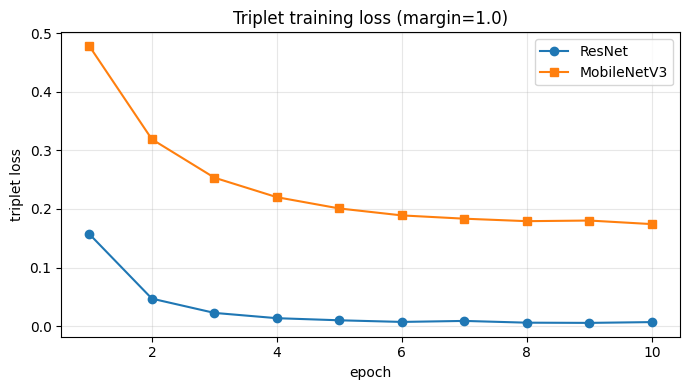

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(hist_resnet)+1),    hist_resnet,    marker='o', label='ResNet')
ax.plot(range(1, len(hist_mobilenet)+1), hist_mobilenet, marker='s', label='MobileNetV3')
ax.set_xlabel('epoch'); ax.set_ylabel('triplet loss')
ax.set_title(f'Triplet training loss (margin={TRIPLET_MARGIN})')
ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 12. Qualitative retrieval — Top-5 per query
For each model (classification vs triplet), show 4 random query images from the query split and their Top-5 gallery hits. Green border = same class as the query, red border = different class.

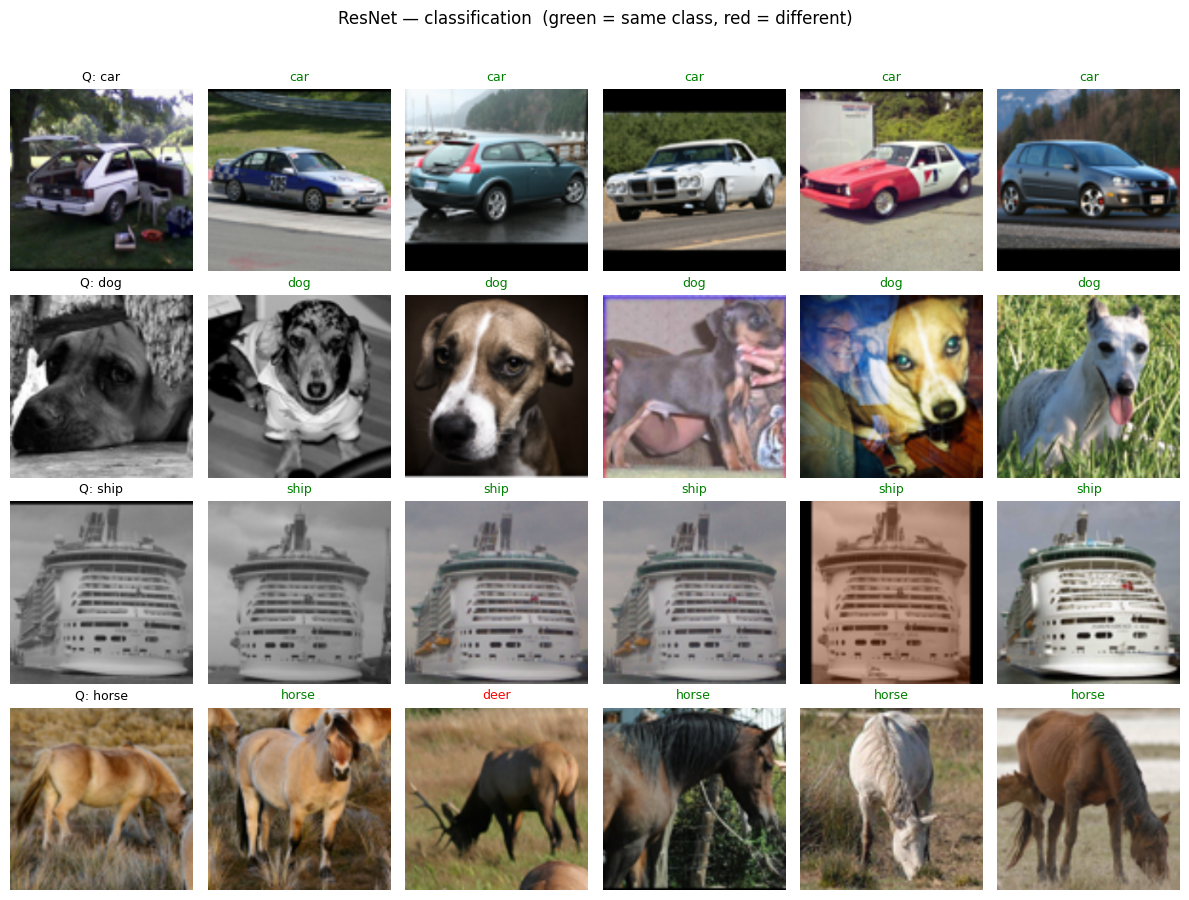

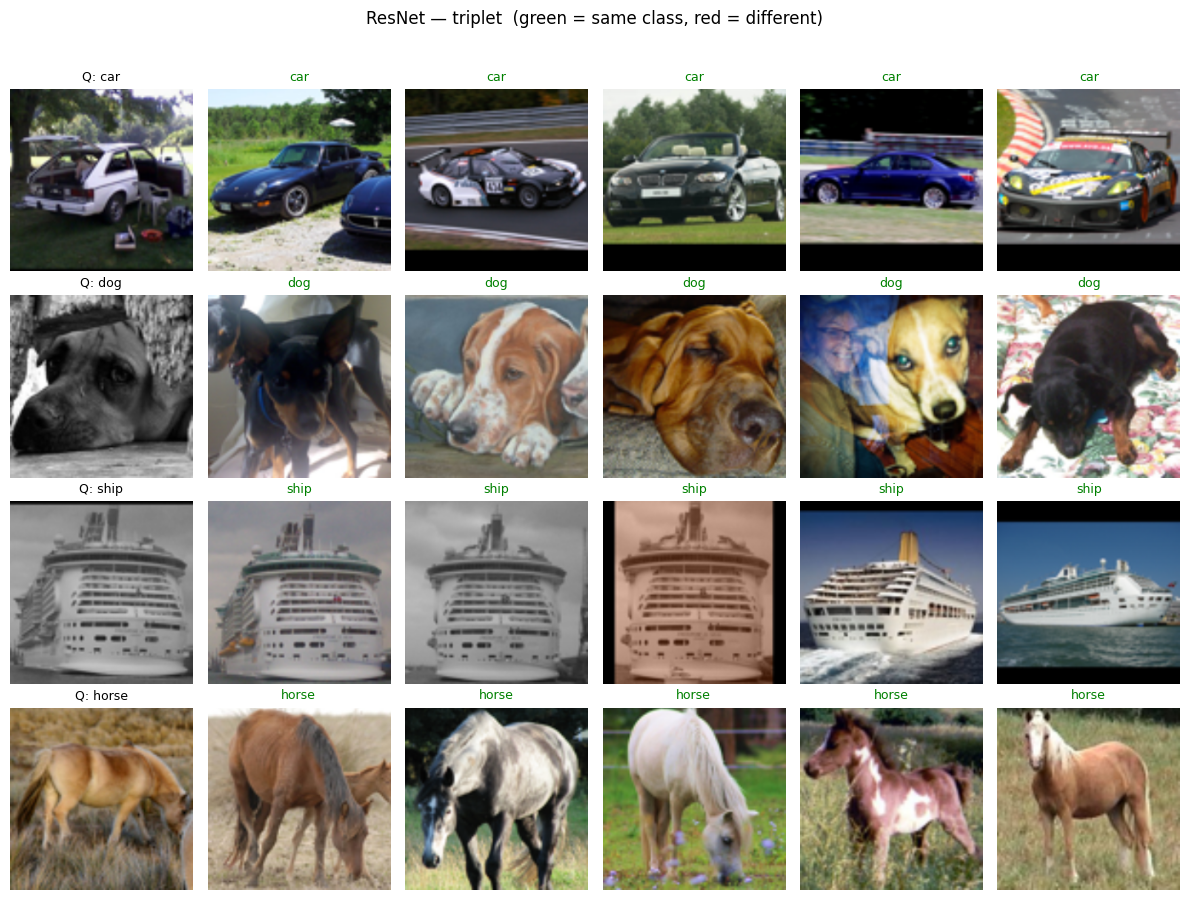

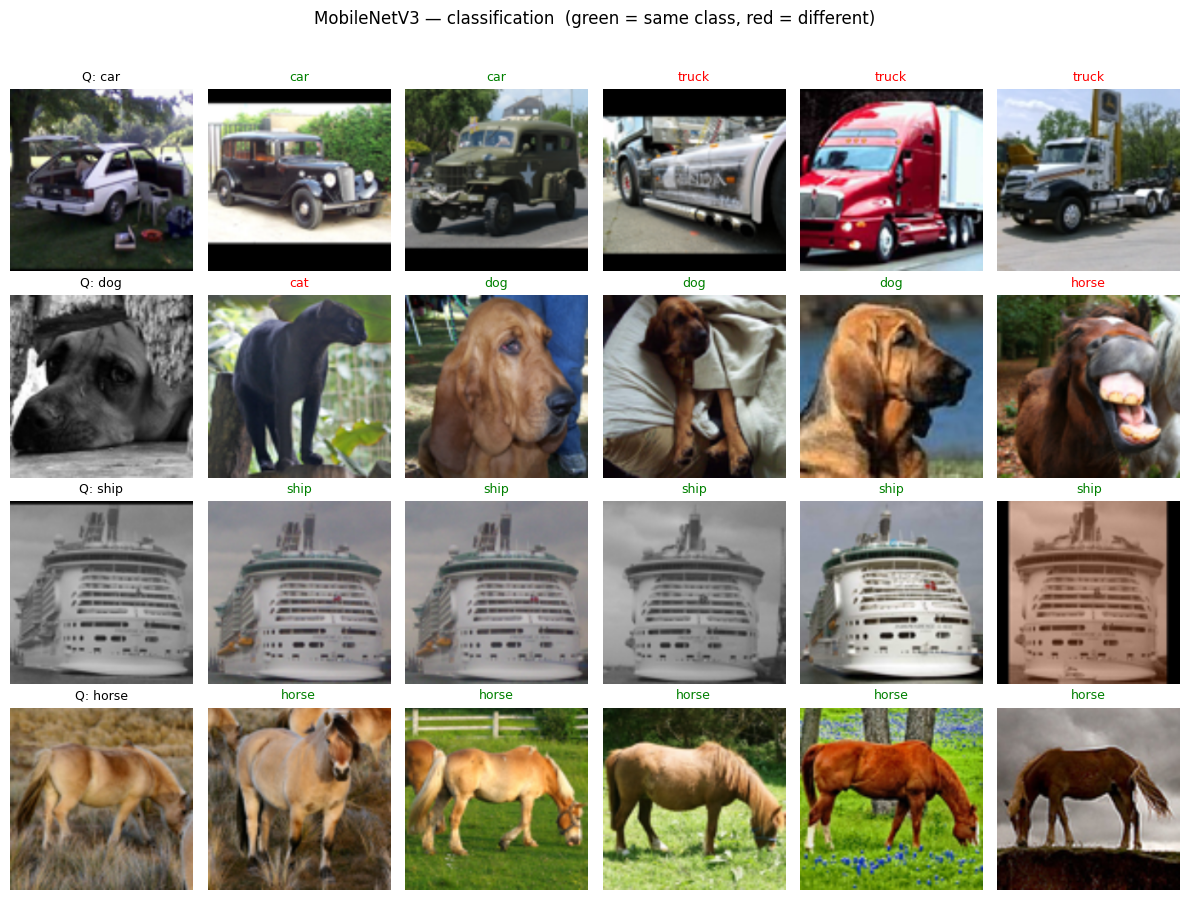

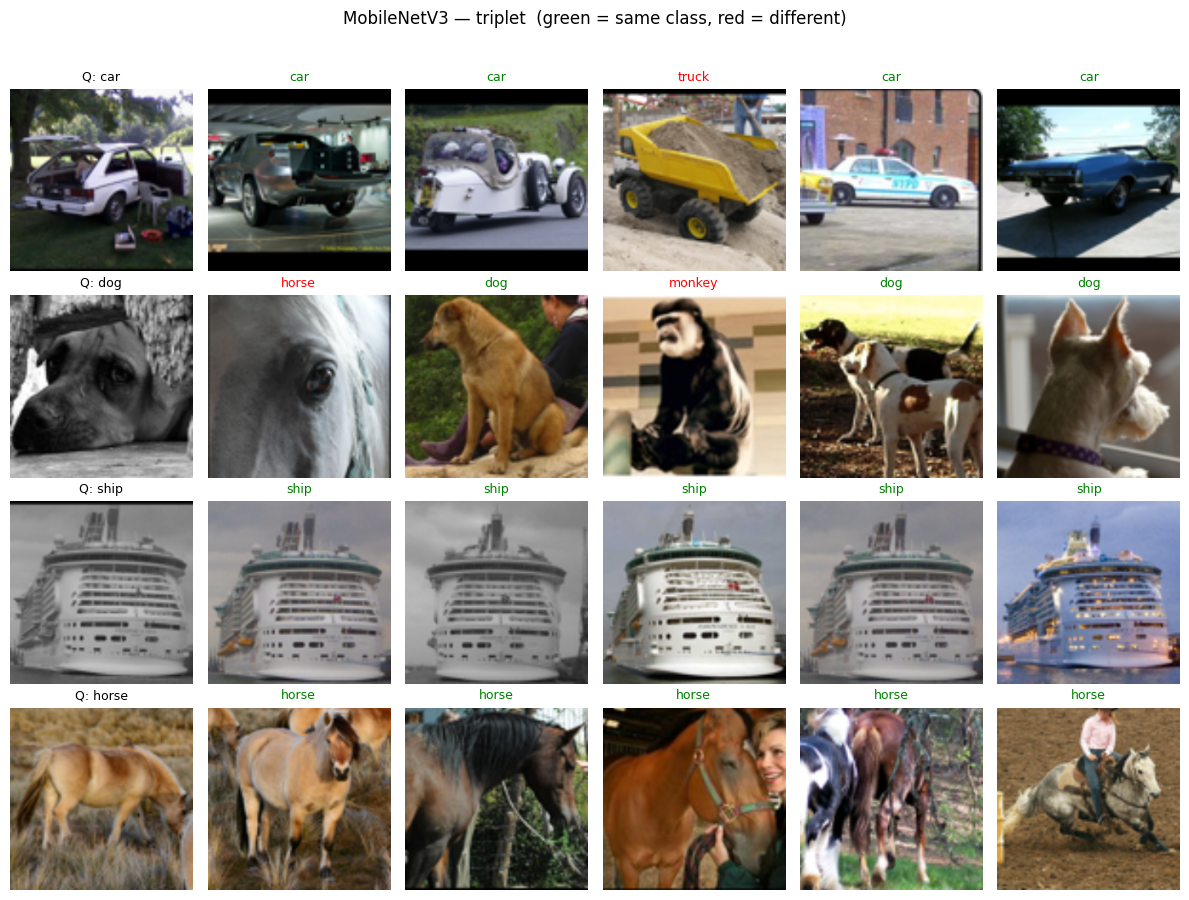

In [30]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# raw STL-10 test set (no normalization) for visualization
raw_test = STL10(root='./data', split='test', download=False, transform=tt.Compose([tt.Resize(IMG_SIZE), tt.ToTensor()]))

def top_k_indices(query_emb, gallery_emb, k=TOP_K):
    q = F.normalize(query_emb.float(), dim=1)
    g = F.normalize(gallery_emb.float(), dim=1)
    return (q @ g.T).argsort(dim=1, descending=True)[:, :k]

def show_retrieval(name, source, query_emb, gallery_emb, q_labels, g_labels, n_queries=4, seed=0):
    rng = np.random.default_rng(seed)
    picks = rng.choice(len(query_emb), size=n_queries, replace=False)
    top_k = top_k_indices(query_emb, gallery_emb)

    fig, axes = plt.subplots(n_queries, TOP_K + 1, figsize=(2.0*(TOP_K+1), 2.2*n_queries))
    for row, qi in enumerate(picks):
        q_img, _ = raw_test[int(query_idx[qi])]
        axes[row, 0].imshow(q_img.permute(1,2,0).numpy())
        axes[row, 0].set_title(f'Q: {classes[int(q_labels[qi])]}', fontsize=9)
        axes[row, 0].axis('off')
        for col, gi in enumerate(top_k[qi].tolist(), start=1):
            g_img, _ = raw_test[int(gallery_idx[gi])]
            same = int(g_labels[gi]) == int(q_labels[qi])
            axes[row, col].imshow(g_img.permute(1,2,0).numpy())
            axes[row, col].set_title(classes[int(g_labels[gi])], fontsize=9,
                                     color=('green' if same else 'red'))
            axes[row, col].axis('off')
            for s in axes[row, col].spines.values():
                s.set_edgecolor('green' if same else 'red'); s.set_linewidth(2)
    fig.suptitle(f'{name} — {source}  (green = same class, red = different)', y=1.02)
    plt.tight_layout(); plt.show()

for name in ('ResNet', 'MobileNetV3'):
    show_retrieval(name, 'classification',
                   retrieval[name]['query_emb'], retrieval[name]['gallery_emb'],
                   query_labels, gallery_labels)
    show_retrieval(name, 'triplet',
                   triplet_embeddings[name]['query'], triplet_embeddings[name]['gallery'],
                   triplet_embeddings[name]['q_labels'], triplet_embeddings[name]['g_labels'])

## 12. Discussion

**Does the best classifier produce the best retrieval representation?**
Not strictly. In Part II MobileNetV3 (95.4%) slightly beat ResNet-18 (95.0%) on classification accuracy, and its classification embeddings also give the highest P@1 (96.06 vs 94.88). However, for mAP (which considers the full ranking, not just the top hits) ResNet-18 wins on classification embeddings (92.08 vs 90.77), so "best classifier" and "best retriever" are not the same thing — the softmax head only needs the correct class to be the top logit, not for intra-class samples to be tightly packed in feature space.

**Effect of the training objective on the embedding space.**
Cross-entropy pushes each class towards a hyperplane that separates it from the rest; it does not explicitly force same-class samples to be close in Euclidean/cosine space, nor negatives to be far by a fixed margin. Triplet loss optimises exactly that geometry: `d(a, p) + margin < d(a, n)`. With `margin=1.0` the loss curves drop smoothly and plateau above zero (ResNet ≈ 0.007, MobileNetV3 ≈ 0.17 after 10 epochs), meaning the optimiser is still finding violating triplets — a healthy regime.

**Does metric learning improve retrieval?**
Yes for ranking quality, mixed for the very top of the ranking.

| Model | Metric | Classification | Triplet (m=1.0) | Δ |
|---|---|---|---|---|
| ResNet-18 | P@1 | 94.88 | 94.13 | -0.75 |
| ResNet-18 | P@5 | 94.38 | 94.11 | -0.27 |
| ResNet-18 | mAP | 92.08 | **93.82** | **+1.74** |
| MobileNetV3 | P@1 | 96.06 | 93.81 | -2.25 |
| MobileNetV3 | P@5 | 95.34 | 93.77 | -1.57 |
| MobileNetV3 | mAP | 90.77 | **94.03** | **+3.26** |

mAP improves for both backbones, which matches the geometric intuition: triplet packs each class into a tighter cluster, so the *entire* ranked gallery contains fewer out-of-class interlopers. P@1 drops slightly — the classification head already excelled at putting the single most confident same-class image on top; globally reshaping the space to improve recall over the full gallery costs a small amount of top-1 precision.

**Margin sensitivity (see `test1`, `test2`, `test3`).**
- `m=0.2`: loss collapses to ≈ 0 immediately — Part II features already satisfy the margin, so no gradient flows and the model barely moves (ResNet mAP 88.80, actually worse than classification).
- `m=1.0`: smooth drop, meaningful residual loss, best overall mAP for both backbones. Chosen configuration.
- `m=2.0`: loss plateaus high (ResNet ≈ 0.63, MobileNetV3 ≈ 1.17), the margin is unreachable with L2-normalised embeddings (whose squared distances are bounded by 4), so the optimiser spends capacity on triplets it cannot satisfy and mAP drops slightly below `m=1.0`.

**Qualitative behaviour.**
In the retrieved Top-5 panels, mistakes made by the classification embeddings tend to be semantically plausible confusions driven by background or pose (e.g. ships retrieved for airplanes with sky/water backgrounds, dogs retrieved for cats in similar poses). The triplet-trained embeddings reduce the number of mixed classes inside each Top-5, which is what increases mAP; occasionally a visually atypical same-class example that the classification embedding ranked first gets displaced by a more prototypical one, explaining the small P@1 loss.